In [1]:
from pathlib import Path

import cartopy.crs as ccrs
from cartopy.feature import LAND
import matplotlib.pyplot as plt
from matplotlib.collections import LineCollection
from matplotlib.colors import Normalize
import numpy as np
import pandas as pd

POINTS_PATH = Path("../data/points.feather")
GRID_RESOLUTION_M = 25_000
SECONDS_PER_DAY = 86_400

CENTER_X_M = 700_000
CENTER_Y_M = -800_000
BUFFER_M = 200_000


## Load the LiMOSAT trajectory table

    This notebook how to convert point trajectories into a regular grid, the size can be adjusted though not smaller than the native resolution of the data which is spatially variable. The velocity calculation is used an example: it uses consecutive points within each trajectory and converts displacement to metres per day. Other parameters can be gridded.



In [2]:
df = (
    pd.read_feather(POINTS_PATH)
    .assign(d=lambda x: pd.to_datetime(x.d))
    .sort_values(["g", "d"])
    .reset_index(drop=True)
)

df.head()


## Compute segment velocities

For each trajectory, the next point defines a displacement segment. Segment midpoint coordinates are used to assign the velocity to a grid cell.


In [3]:
segments = df.copy()
segments[["x2", "y2", "d2"]] = segments.groupby("g")[["x", "y", "d"]].shift(-1)
segments = segments.dropna(subset=["x2", "y2", "d2"]).copy()

segments["dt_seconds"] = (segments.d2 - segments.d).dt.total_seconds()
segments = segments[segments.dt_seconds > 0].copy()

segments["xm"] = (segments.x + segments.x2) / 2
segments["ym"] = (segments.y + segments.y2) / 2
segments["u"] = (segments.x2 - segments.x) / segments.dt_seconds
segments["v"] = (segments.y2 - segments.y) / segments.dt_seconds
segments["speed"] = np.hypot(segments.u, segments.v)
segments["speed_m_day"] = segments.speed * SECONDS_PER_DAY
segments["dist_m"] = np.hypot(segments.x2 - segments.x, segments.y2 - segments.y)
segments["track_len_m"] = segments.groupby("g").dist_m.transform("sum")
segments["xg"] = np.floor(segments.xm / GRID_RESOLUTION_M) * GRID_RESOLUTION_M
segments["yg"] = np.floor(segments.ym / GRID_RESOLUTION_M) * GRID_RESOLUTION_M
segments["t"] = segments.d.dt.floor("D")

segments[["g", "d", "x", "y", "x2", "y2", "u", "v", "speed_m_day", "xg", "yg", "t"]].head()


## Aggregate to a daily 25 km grid

The grid stores the mean vector components for each day and grid cell. Speed is recomputed from the gridded mean vector components.


In [4]:
grid = segments.groupby(["t", "xg", "yg"], as_index=False).agg(
    u=("u", "mean"),
    v=("v", "mean"),
    n=("g", "count"),
    q=("q", "mean"),
)
grid["speed"] = np.hypot(grid.u, grid.v)
grid["speed_m_day"] = grid.speed * SECONDS_PER_DAY

grid.head()


In [5]:
summary = pd.Series({
    "input_points": len(df),
    "trajectory_count": df.g.nunique(),
    "velocity_segments": len(segments),
    "daily_grid_cells": len(grid),
    "date_min": grid.t.min(),
    "date_max": grid.t.max(),
    "grid_resolution_m": GRID_RESOLUTION_M,
})
summary


## Plot trajectories and grid-cell speed

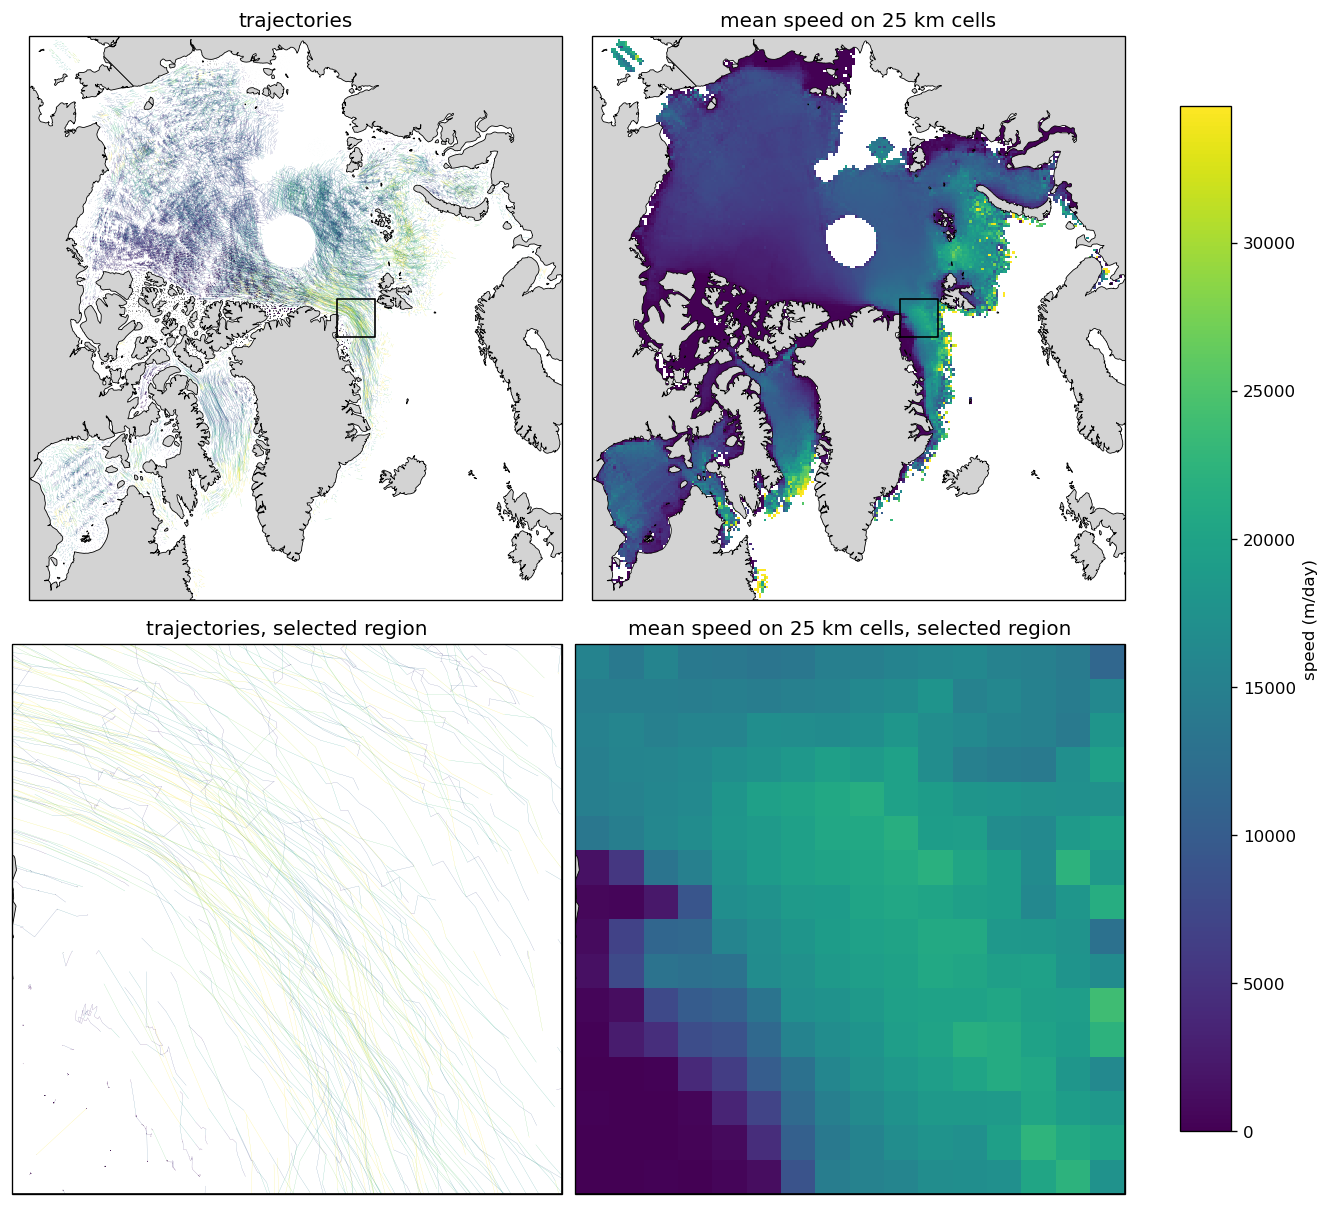

In [6]:
def bounds_from_center(center_x_m, center_y_m, buffer_m):
    return (center_x_m - buffer_m, center_x_m + buffer_m), (center_y_m - buffer_m, center_y_m + buffer_m)


def line_collection_from_segments(frame, norm, projection):
    xy = frame[["x", "y", "x2", "y2"]].to_numpy(dtype=float).reshape(-1, 2, 2)
    collection = LineCollection(
        xy,
        cmap="viridis",
        norm=norm,
        linewidths=0.12,
        alpha=0.7,
        transform=projection,
        zorder=1,
    )
    collection.set_array(frame.speed_m_day.to_numpy(dtype=float))
    return collection


def grid_speed_array(cell_values, resolution_m):
    x_min = float(cell_values.xg.min())
    x_max = float(cell_values.xg.max())
    y_min = float(cell_values.yg.min())
    y_max = float(cell_values.yg.max())
    x_edges = np.arange(x_min, x_max + 2 * resolution_m, resolution_m)
    y_edges = np.arange(y_min, y_max + 2 * resolution_m, resolution_m)
    speed = np.full((len(y_edges) - 1, len(x_edges) - 1), np.nan)
    x_index = ((cell_values.xg.to_numpy() - x_min) / resolution_m).astype(int)
    y_index = ((cell_values.yg.to_numpy() - y_min) / resolution_m).astype(int)
    speed[y_index, x_index] = cell_values.speed_m_day.to_numpy(dtype=float)
    return x_edges, y_edges, speed


def add_query_box(ax, xlim_m, ylim_m, projection):
    box_x = [xlim_m[0], xlim_m[1], xlim_m[1], xlim_m[0], xlim_m[0]]
    box_y = [ylim_m[0], ylim_m[0], ylim_m[1], ylim_m[1], ylim_m[0]]
    ax.plot(box_x, box_y, color="black", linewidth=1.0, transform=projection, zorder=4)


trajectory_ids = segments.loc[
    segments.groupby(["xg", "yg"]).track_len_m.idxmax(), "g"
].unique()
trajectory_segments = segments.loc[segments.g.isin(trajectory_ids)].copy()

cell_mean = grid.groupby(["xg", "yg"], as_index=False).agg(
    speed_m_day=("speed_m_day", "mean"),
    observations=("n", "sum"),
)

region_xlim, region_ylim = bounds_from_center(CENTER_X_M, CENTER_Y_M, BUFFER_M)
full_xlim = (cell_mean.xg.min() - GRID_RESOLUTION_M, cell_mean.xg.max() + 2 * GRID_RESOLUTION_M)
full_ylim = (cell_mean.yg.min() - GRID_RESOLUTION_M, cell_mean.yg.max() + 2 * GRID_RESOLUTION_M)

vmax = np.nanquantile(
    np.r_[trajectory_segments.speed_m_day.to_numpy(), cell_mean.speed_m_day.to_numpy()],
    0.995,
)
norm = Normalize(0, vmax, clip=True)
x_edges, y_edges, speed_grid = grid_speed_array(cell_mean, GRID_RESOLUTION_M)
projection = ccrs.NorthPolarStereo(central_longitude=-45, true_scale_latitude=70.0)

fig, axes = plt.subplots(2, 2, figsize=(11, 10), subplot_kw={"projection": projection}, constrained_layout=True)

for ax in axes.flat:
    ax.add_feature(LAND, zorder=2, edgecolor="black", facecolor="lightgray", linewidth=0.5)

axes[0, 0].add_collection(line_collection_from_segments(trajectory_segments, norm, projection))
add_query_box(axes[0, 0], region_xlim, region_ylim, projection)
axes[0, 0].set_title("trajectories")

grid_plot = axes[0, 1].pcolormesh(
    x_edges,
    y_edges,
    speed_grid,
    cmap="viridis",
    norm=norm,
    shading="flat",
    transform=projection,
    zorder=1,
)
add_query_box(axes[0, 1], region_xlim, region_ylim, projection)
axes[0, 1].set_title(f"mean speed on {GRID_RESOLUTION_M // 1000} km cells")

axes[1, 0].add_collection(line_collection_from_segments(trajectory_segments, norm, projection))
add_query_box(axes[1, 0], region_xlim, region_ylim, projection)
axes[1, 0].set_title("trajectories, selected region")

axes[1, 1].pcolormesh(
    x_edges,
    y_edges,
    speed_grid,
    cmap="viridis",
    norm=norm,
    shading="flat",
    transform=projection,
    zorder=1,
)
add_query_box(axes[1, 1], region_xlim, region_ylim, projection)
axes[1, 1].set_title(f"mean speed on {GRID_RESOLUTION_M // 1000} km cells, selected region")

for ax in axes.flat:
    ax.set_xlabel("x EPSG:3413 (m)")
    ax.set_ylabel("y EPSG:3413 (m)")

for ax in axes[0, :]:
    ax.set_extent([full_xlim[0], full_xlim[1], full_ylim[0], full_ylim[1]], crs=projection)

for ax in axes[1, :]:
    ax.set_extent([region_xlim[0], region_xlim[1], region_ylim[0], region_ylim[1]], crs=projection)

fig.colorbar(grid_plot, ax=axes, label="speed (m/day)", shrink=0.88)

plt.show()
